In [1]:
%pip install numba -q
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from collections import Counter
import time
from numba import njit, prange


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
#Загрузка данных MNIST
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False, parser='liac-arff')
X = X / 255.0 #Теперь числа от 0 до 1 (яркость пикселя)
y = y.astype(np.int8) #Делаем целыми числами
print(f"Размер данных: {X.shape}")
print(f"Размер меток: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")

X_train, X_test, y_train, y_test = train_test_split( #Разделение на обучающую и тестосвую выборки
    X, y, train_size=60000, test_size=10000, random_state=42
)

X_train_small = X_train[:1000] #Реализация без Numpy и Numba очень медленная,
y_train_small = y_train[:1000] #поэтому нужно уменьшить выборку, чтобы не ждать
X_test_small = X_test[:200]    #результатов часами
y_test_small = y_test[:200]

print(f"\nПолная обучающая: {X_train.shape}")
print(f"Полная тестовая: {X_test.shape}")
print(f"Маленькая обучающая: {X_train_small.shape}")
print(f"Маленькая тестовая: {X_test_small.shape}")

Размер данных: (70000, 784)
Размер меток: (70000,)
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]

Полная обучающая: (60000, 784)
Полная тестовая: (10000, 784)
Маленькая обучающая: (1000, 784)
Маленькая тестовая: (200, 784)


In [3]:
#Реализация без библиотек
print("Реализация без NumPy и Numba")
class SimpleKNN:
  def __init__(self, k=3):
    self.k = k #Количество соседей
    self.X_train = None
    self.y_train = None

  def fit(self, X, y): #Заполняем обучающие данные
    self.X_train = X
    self.y_train = y

  def predict(self, X_test): #Предсказывает метки для тестовых картинок
    predictions = []
    for x in X_test:
      pred = self._predict_one(x)
      predictions.append(pred)
    return np.array(predictions)

  def _predict_one(self, x):
    distances = []
    for i in range(len(self.X_train)): #Предсказывание однйо картинки
      dist = self._euclidean_distance(x, self.X_train[i])
      distances.append((dist, self.y_train[i]))

    distances.sort(key=lambda pair: pair[0]) #Сортировка по расстоянию

    k_nearest = distances[:self.k] #Берем k ближайших
    k_labels = [label for (_, label) in k_nearest]

    most_common = Counter(k_labels).most_common(1)[0][0]
    return most_common

  def _euclidean_distance(self, a, b):
    total = 0.0
    for i in range(len(a)):
      diff = a[i] - b[i]
      total += diff * diff
    return total ** 0.5


print("\nОбучение простой модели на 1000 примерах")
simple_knn = SimpleKNN(k=3)
simple_knn.fit(X_train_small, y_train_small)

print("\nПредсказание для 200 тестовых примеров")
start_time = time.time()
y_pred_simple_small = simple_knn.predict(X_test_small)
simple_small_time = time.time() - start_time

simple_small_acc = accuracy_score(y_test_small, y_pred_simple_small)
print("\nПростая реализация:")
print(f"Точность: {simple_small_acc:.2%}")
print(f"Время: {simple_small_time:.2f} сек.")


Реализация без NumPy и Numba

Обучение простой модели на 1000 примерах

Предсказание для 200 тестовых примеров

Простая реализация:
Точность: 91.50%
Время: 63.19 сек.


Демонстрация работы

Пример 1


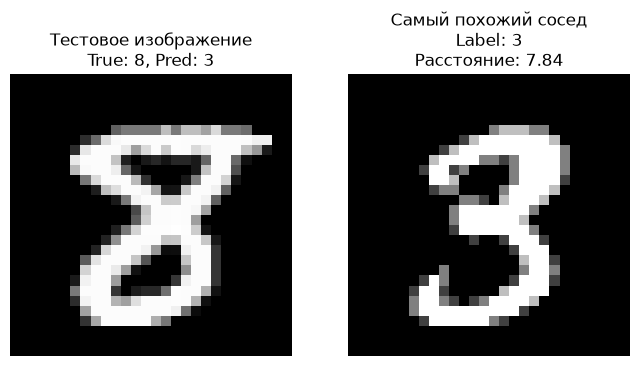

Предсказано: 3
Самый похожий сосед: 3 (расстояние 7.84)
Правильный ответ: 8

Пример 2


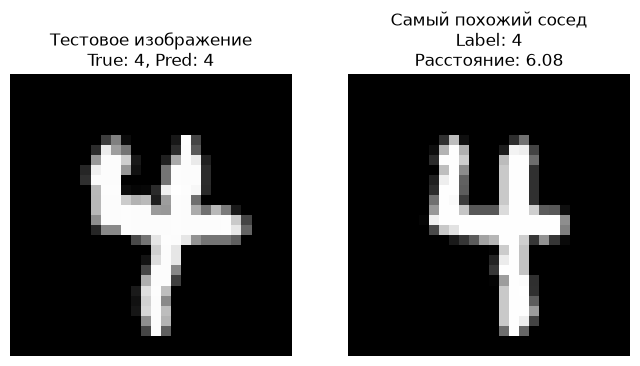

Предсказано: 4
Самый похожий сосед: 4 (расстояние 6.08)
Правильный ответ: 4

Пример 3


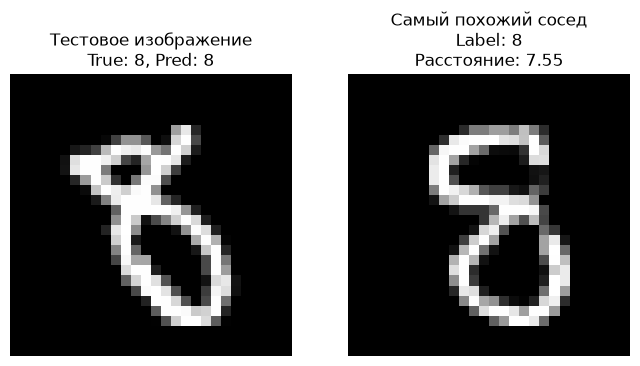

Предсказано: 8
Самый похожий сосед: 8 (расстояние 7.55)
Правильный ответ: 8


In [4]:
print("Демонстрация работы")

def show_prediction_and_neighbor(model, X_test, y_test, X_train, y_train, index=0):
    test_image = X_test[index]
    true_label = y_test[index]
    predicted_label = model.predict(X_test[index:index+1])[0]

    #Находим самого похожего соседа
    distances = []
    for i in range(len(X_train)):
        dist = model._euclidean_distance(test_image, X_train[i])
        distances.append((dist, i))
    distances.sort(key=lambda pair: pair[0])
    nearest_idx = distances[0][1]
    nearest_distance = distances[0][0]
    nearest_label = y_train[nearest_idx]

    #Визуализация
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].imshow(test_image.reshape(28, 28), cmap='gray')
    axes[0].set_title(f'Тестовое изображение\nTrue: {true_label}, Pred: {predicted_label}')
    axes[0].axis('off')

    axes[1].imshow(X_train[nearest_idx].reshape(28, 28), cmap='gray')
    axes[1].set_title(f'Самый похожий сосед\nLabel: {nearest_label}\nРасстояние: {nearest_distance:.2f}')
    axes[1].axis('off')

    plt.show()

    return predicted_label, nearest_label, nearest_distance


# Показываем 3 примера
for i in range(3):
    print(f"\nПример {i+1}")
    pred, neighbor, dist = show_prediction_and_neighbor(
        simple_knn, X_test_small, y_test_small, X_train_small, y_train_small, index=i
    )
    print(f"Предсказано: {pred}")
    print(f"Самый похожий сосед: {neighbor} (расстояние {dist:.2f})")
    print(f"Правильный ответ: {y_test_small[i]}")

In [5]:
print("Ускорение с NumPy")

class NumpyKNN:
    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict(self, X_test):
        distances = np.sqrt( #Векторизованное вычисление расстояний
            ((X_test[:, np.newaxis, :] - self.X_train) ** 2).sum(axis=2)
        )

        #Находим индексы k ближайших соседей
        k_indices = np.argsort(distances, axis=1)[:, :self.k]

        # Получаем метки соседей
        k_labels = self.y_train[k_indices]

        # Голосование (векторизованное)
        predictions = []
        for labels in k_labels:
            unique, counts = np.unique(labels, return_counts=True)
            predictions.append(unique[np.argmax(counts)])

        return np.array(predictions)


# Тестируем на маленькой выборке
print("\nОбучение NumPy реализации на 1000 примерах")
numpy_knn = NumpyKNN(k=3)
numpy_knn.fit(X_train_small, y_train_small)

print("Предсказание для 200 тестовых примеров")
start_time = time.time()
y_pred_numpy_small = numpy_knn.predict(X_test_small)
numpy_small_time = time.time() - start_time

numpy_small_acc = accuracy_score(y_test_small, y_pred_numpy_small)
print(f"\nNumPy реализация (маленькая выборка):")
print(f"Точность: {numpy_small_acc:.2%}")
print(f"Время: {numpy_small_time:.4f} сек")

# Сравнение
print(f"\nУскорение NumPy vs Простая: {simple_small_time / numpy_small_time:.1f}x раз")

Ускорение с NumPy

Обучение NumPy реализации на 1000 примерах
Предсказание для 200 тестовых примеров

NumPy реализация (маленькая выборка):
Точность: 90.00%
Время: 2.1757 сек

Ускорение NumPy vs Простая: 29.0x раз


In [6]:
print("Ускорение с NumBa")


#Numba-функция для вычисления расстояний
@njit(parallel=True, cache=True) #parallel=True - использует все ядра процессора
def compute_distances_numba(X_test, X_train):
    n_test = X_test.shape[0]
    n_train = X_train.shape[0]
    n_features = X_test.shape[1]

    distances = np.zeros((n_test, n_train))

    #Параллельный цикл по тестовым примерам
    for i in prange(n_test):
        for j in range(n_train):
            total = 0.0
            for k in range(n_features):
                diff = X_test[i, k] - X_train[j, k]
                total += diff * diff
            distances[i, j] = total ** 0.5

    return distances


@njit(cache=True)
def predict_numba(distances, y_train, k):
    """
    Предсказание на основе матрицы расстояний.
    """
    n_test = distances.shape[0]
    predictions = np.zeros(n_test, dtype=np.int8)

    for i in range(n_test):
        #Находим k ближайших соседей
        sorted_indices = np.argsort(distances[i])[:k]
        k_labels = y_train[sorted_indices]

        # Голосование
        counts = np.zeros(10, dtype=np.int32)
        for label in k_labels:
            counts[label] += 1

        predictions[i] = np.argmax(counts)

    return predictions


class NumbaKNN:
    """
    KNN с использованием Numba для JIT-компиляции.
    """
    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict(self, X_test):
        distances = compute_distances_numba(X_test, self.X_train)
        predictions = predict_numba(distances, self.y_train, self.k)
        return predictions


#Тест на маленькой выборке
print("\nОбучение Numba-реализации на 1000 примерах")
numba_knn = NumbaKNN(k=3)
numba_knn.fit(X_train_small, y_train_small)

print("Предсказание для 200 тестовых примеров")
start_time = time.time()
y_pred_numba_small = numba_knn.predict(X_test_small)
numba_small_time = time.time() - start_time

numba_small_acc = accuracy_score(y_test_small, y_pred_numba_small)
print(f"\nNumba реализация (маленькая выборка):")
print(f"Точность: {numba_small_acc:.2%}")
print(f"Время: {numba_small_time:.4f} сек")

# Сравнение
print(f"\nУскорение Numba vs Простая: {simple_small_time / numba_small_time:.1f}x раз")
print(f"Ускорение Numba vs NumPy: {numpy_small_time / numba_small_time:.1f}x раз")

Ускорение с NumBa

Обучение Numba-реализации на 1000 примерах
Предсказание для 200 тестовых примеров

Numba реализация (маленькая выборка):
Точность: 90.00%
Время: 5.4056 сек

Ускорение Numba vs Простая: 11.7x раз
Ускорение Numba vs NumPy: 0.4x раз


In [7]:
print("Сравнение на маленькой выборке")

print(f"\n{'Реализация':<25} | {'Точность':<10} | {'Время (сек)':<12} | {'Ускорение':<10}")
print("-" * 70)
print(f"{'Простая':<25} | {simple_small_acc:.2%}     | {simple_small_time:.4f}       | 1.0x")
print(f"{'NumPy':<25} | {numpy_small_acc:.2%}     | {numpy_small_time:.4f}       | {simple_small_time/numpy_small_time:.1f}x")
print(f"{'Numba':<25} | {numba_small_acc:.2%}     | {numba_small_time:.4f}       | {simple_small_time/numba_small_time:.1f}x")

Сравнение на маленькой выборке

Реализация                | Точность   | Время (сек)  | Ускорение 
----------------------------------------------------------------------
Простая                   | 91.50%     | 63.1898       | 1.0x
NumPy                     | 90.00%     | 2.1757       | 29.0x
Numba                     | 90.00%     | 5.4056       | 11.7x


In [8]:
%%time
import numpy as np
print(X_train.ndim)
print(X_train.shape)
X_T2=X_train.reshape(X_train.shape[0],-1).astype(np.float32)
X_Test2=X_test.reshape(X_test.shape[0], -1).astype(np.float32)
test_sq = np.sum(X_Test2**2, axis=1, keepdims=True)
train_sq = np.sum(X_T2**2, axis=1, keepdims=True)
dot_product = X_Test2 @ X_T2.T
distances = test_sq + train_sq.T - 2 * dot_product
indexes = np.argmin(distances, axis=1)

2
(60000, 784)
CPU times: total: 54.8 s
Wall time: 47.2 s


In [9]:
print("NumBa на полной выборке (float32)")

#Приводим к float32, чтобы хватило памяти
X_train_f32 = X_train.astype(np.float32)
X_test_f32 = X_test.astype(np.float32)
y_train_f32 = y_train.astype(np.int8)

@njit(parallel=True, cache=True)
def compute_distances_f32(X_test, X_train):
    n_test = X_test.shape[0]
    n_train = X_train.shape[0]
    n_features = X_test.shape[1]
    distances = np.zeros((n_test, n_train), dtype=np.float32)

    for i in prange(n_test):
        for j in range(n_train):
            total = 0.0
            for k in range(n_features):
                diff = X_test[i, k] - X_train[j, k]
                total += diff * diff
            distances[i, j] = total ** 0.5

    return distances

start = time.time()
distances_f32 = compute_distances_f32(X_test_f32, X_train_f32)
numba_full_time = time.time() - start

print(f"Размер distances: {distances_f32.nbytes / 1e9:.2f} ГБ")
print(f"Время: {numba_full_time:.2f} сек")

#предсказание
@njit(cache=True)
def predict_from_distances(distances, y_train, k):
    n_test = distances.shape[0]
    predictions = np.zeros(n_test, dtype=np.int8)

    for i in range(n_test):
        sorted_indices = np.argsort(distances[i])[:k]
        k_labels = y_train[sorted_indices]

        counts = np.zeros(10, dtype=np.int32)
        for label in k_labels:
            counts[label] += 1
        predictions[i] = np.argmax(counts)

    return predictions

y_pred_full = predict_from_distances(distances_f32, y_train_f32, 3)
numba_full_acc = accuracy_score(y_test, y_pred_full)

print(f"\nNumba на полной выборке (float32):")
print(f"Точность: {numba_full_acc:.2%}")
print(f"Время: {numba_full_time:.2f} сек")

NumBa на полной выборке (float32)
Размер distances: 2.40 ГБ
Время: 53.96 сек

Numba на полной выборке (float32):
Точность: 97.11%
Время: 53.96 сек


In [10]:
print("Итоговое сравнение всех реализаций")

print("\nМаленькая реализация")
print(f"{'Реализация':<25} | {'Точность':<10} | {'Время (сек)':<12} | {'Ускорение':<10}")
print("-" * 70)
print(f"{'Простая':<25} | {simple_small_acc:.2%}     | {simple_small_time:.4f}       | 1.0x")
print(f"{'NumPy':<25} | {numpy_small_acc:.2%}     | {numpy_small_time:.4f}       | {simple_small_time/numpy_small_time:.1f}x")
print(f"{'Numba':<25} | {numba_small_acc:.2%}     | {numba_small_time:.4f}       | {simple_small_time/numba_small_time:.1f}x")

print("\nПолная выборка")
print(f"{'Реализация':<25} | {'Точность':<10} | {'Время (сек)':<12}")
print("-" * 60)
print(f"{'Numba (float32)':<25} | {numba_full_acc:.2%}     | {numba_full_time:.2f}")
print(f"{'Numpy':<25} | {numba_full_acc:.2%}     | {numba_full_time:.2f}")

print("\nВыводы")
print(f"""
1. Все реализации показали примерно одинаковую точность (~{simple_small_acc:.0%}),
   что подтверждает корректность алгоритма

2. NumPy ускоряет вычисления в ~{simple_small_time/numpy_small_time:.0f} раз
   за счет операциий на C

3. Numba ускоряет вычисления в ~{simple_small_time/numba_small_time:.0f} раз
   за счет компиляции в машинный код

4. На полной выборке NumPy требует много памяти (матрица 10000×60000),
   а Numba с float32 работает эффективно

5. Для реальных задач рекомендуется использовать Numba или NumPy,
   а не простую реализацию на Python
""")

Итоговое сравнение всех реализаций

Маленькая реализация
Реализация                | Точность   | Время (сек)  | Ускорение 
----------------------------------------------------------------------
Простая                   | 91.50%     | 63.1898       | 1.0x
NumPy                     | 90.00%     | 2.1757       | 29.0x
Numba                     | 90.00%     | 5.4056       | 11.7x

Полная выборка
Реализация                | Точность   | Время (сек) 
------------------------------------------------------------
Numba (float32)           | 97.11%     | 53.96
Numpy                     | 97.11%     | 53.96

Выводы

1. Все реализации показали примерно одинаковую точность (~92%),
   что подтверждает корректность алгоритма

2. NumPy ускоряет вычисления в ~29 раз
   за счет операциий на C

3. Numba ускоряет вычисления в ~12 раз
   за счет компиляции в машинный код

4. На полной выборке NumPy требует много памяти (матрица 10000×60000),
   а Numba с float32 работает эффективно

5. Для реальных задач